# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

In [ ]:
# Find the DataFrame you've already loaded
dfs = {
    name: obj for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

print("Available DataFrames:", list(dfs.keys()))

for name, data in dfs.items():
    print(f"\n{name}: shape={data.shape}")
    print("Columns:", data.columns.tolist())
    print(data.head(3))

Available DataFrames: ['_', 'tx', '_1']

_: shape=(5, 13)
Columns: ['txn_id', 'timestamp', 'day', 'hour', 'customer_id', 'city', 'merchant_category', 'amount_inr', 'distance_from_home_km', 'detector_score', 'is_fraud', 'night', 'label']
   txn_id           timestamp  day  hour customer_id       city  \
0  T00001 2026-06-01 02:39:00    1     2       C0618    Chennai   
1  T00002 2026-06-01 02:58:00    1     2       C0769  Bengaluru   
2  T00003 2026-06-01 02:46:00    1     2       C0104      Delhi   

  merchant_category  amount_inr  distance_from_home_km  detector_score  \
0         Groceries      1666.0                    5.2          0.2050   
1            Travel     11733.0                    4.7          0.2322   
2       Electronics     22342.0                 1026.0          0.9932   

   is_fraud  night       label  
0         0   True  legitimate  
1         0   True  legitimate  
2         0   True  legitimate  

tx: shape=(5520, 13)
Columns: ['txn_id', 'timestamp', 'day', 'ho

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ The overview revealed patterns across the entire month, such as unusual spikes in daily fraud and concentrations of fraud on particular days or in particular cities, which an alert list sorted by detector score would hide. The lecture concept is reordering (Slide 39): sorting the city and day axes by their total fraud counts makes clusters and unusual patterns easier to spot.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

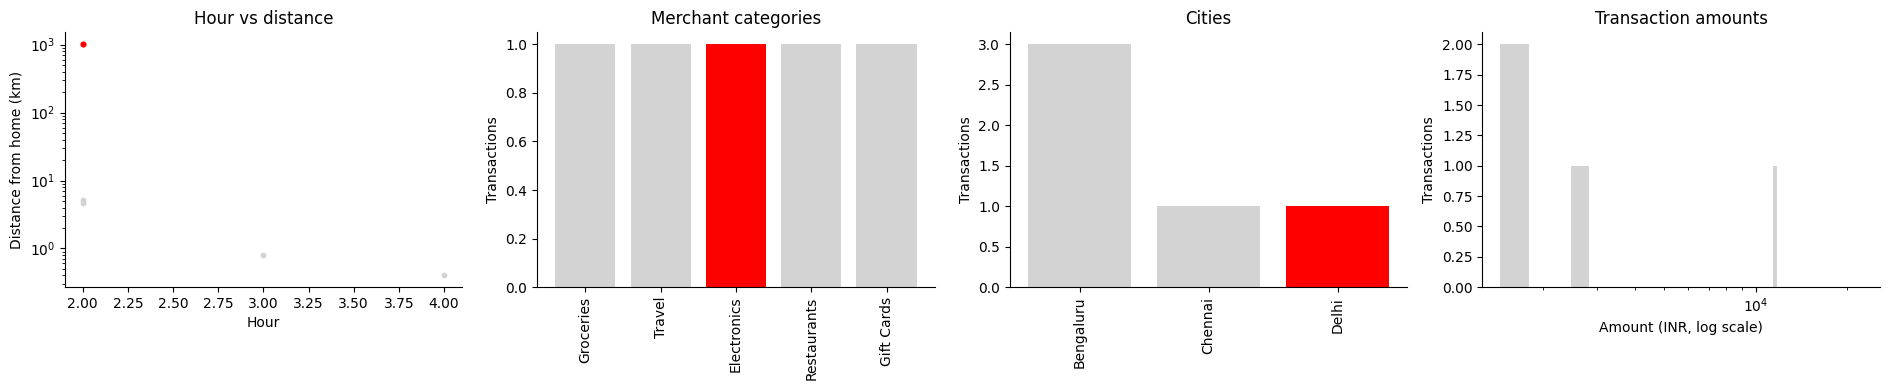

Number brushed: 1
Fraud rate inside brush: 0.00%
Overall fraud rate: 0.00%
Share of all fraud captured by brush: 0.00%


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use your already-loaded DataFrame
df = next(
    obj for obj in globals().values()
    if isinstance(obj, pd.DataFrame)
    and {"hour", "distance_from_home_km", "merchant_category",
         "city", "amount_inr", "is_fraud", "night"}.issubset(obj.columns)
)

# TODO 1: define the brush
brush = df["night"].astype(bool) & (df["distance_from_home_km"] > 100)

# Confirmed fraud labels
fraud = df["is_fraud"].astype(bool)

# TODO 2: four coordinated views
fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# (a) Hour vs distance — log y-axis
axes[0].scatter(
    df.loc[~brush, "hour"], df.loc[~brush, "distance_from_home_km"],
    c="lightgrey", s=10
)
axes[0].scatter(
    df.loc[brush, "hour"], df.loc[brush, "distance_from_home_km"],
    c="red", s=12
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs distance")

# (b) Merchant-category counts
cat_all = df["merchant_category"].value_counts()
cat_brushed = df.loc[brush, "merchant_category"].value_counts()
x = np.arange(len(cat_all))
axes[1].bar(x, cat_all.values, color="lightgrey")
axes[1].bar(
    x, [cat_brushed.get(c, 0) for c in cat_all.index], color="red"
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(cat_all.index, rotation=90)
axes[1].set_title("Merchant categories")
axes[1].set_ylabel("Transactions")

# (c) City counts
city_all = df["city"].value_counts()
city_brushed = df.loc[brush, "city"].value_counts()
x = np.arange(len(city_all))
axes[2].bar(x, city_all.values, color="lightgrey")
axes[2].bar(
    x, [city_brushed.get(c, 0) for c in city_all.index], color="red"
)
axes[2].set_xticks(x)
axes[2].set_xticklabels(city_all.index, rotation=90)
axes[2].set_title("Cities")
axes[2].set_ylabel("Transactions")

# (d) Amount histogram — log10 x-axis
amount = pd.to_numeric(df["amount_inr"], errors="coerce")
valid = amount.notna() & (amount > 0)
axes[3].hist(amount[valid & ~brush], bins=30, color="lightgrey")
axes[3].hist(amount[valid & brush], bins=30, color="red")
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_ylabel("Transactions")
axes[3].set_title("Transaction amounts")

plt.tight_layout()
plt.show()

# TODO 3: summary statistics
n_brushed = int(brush.sum())
n_fraud = int(fraud.sum())

fraud_inside = fraud[brush].mean() if n_brushed else 0.0
fraud_overall = fraud.mean()
share_fraud_captured = (
    (fraud & brush).sum() / n_fraud if n_fraud else 0.0
)

print(f"Number brushed: {n_brushed:,}")
print(f"Fraud rate inside brush: {fraud_inside:.2%}")
print(f"Overall fraud rate: {fraud_overall:.2%}")
print(f"Share of all fraud captured by brush: {share_fraud_captured:.2%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_The brush may have a high fraud rate, but its share of all fraud captured tells us how much total fraud it actually catches. If that share is low, investigators should not rely on the night-time, far-from-home rule alone, because many fraud cases fall outside it. The merchant-category or city linked view may reveal where the remaining fraud is concentrated among unbrushed transactions

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [ ]:
import time

big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Best filtering time across 5 runs
times = []

for _ in range(5):
    start = time.perf_counter()
    result = big.loc[
        (big["detector_score"] >= 0.6) &
        (big["amount_inr"] > 3000)
    ]
    elapsed = time.perf_counter() - start
    times.append(elapsed)

best_s = min(times)

# TODO 2: Per-item cost and maximum rows within 0.1 seconds
per_item_us = (best_s / len(big)) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3: Estimate for 50 million rows
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0, (1 - max_rows / 50_000_000) * 100)

print(
    f"{len(big):,} rows in {best_s*1000:.1f} ms "
    f"-> {per_item_us:.4f} us/row "
    f"-> max {max_rows:,.0f} rows in 0.1 s"
)
print(
    f"50M rows -> {t_50m:.2f} s; "
    f"must skip {skip_pct:.1f}% of rows to stay under 0.1 s"
)

1,004,640 rows in 11.3 ms -> 0.0113 us/row -> max 8,851,764 rows in 0.1 s
50M rows -> 0.56 s; must skip 82.3% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ One reduce technique is sampling — instead of filtering all 50 million transactions, the slider queries a representative subset. This can keep interactions fast, but the analyst may miss rare fraud cases or small clusters, so the results may not represent the full dataset accurately.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

Capacity-constrained choice:
threshold      0.800000
alerts       144.000000
TP            84.000000
FP            60.000000
FN            36.000000
precision      0.583333
recall         0.700000
F1             0.636364
Name: 15, dtype: float64

Best-F1 choice:
threshold      0.850000
alerts       128.000000
TP            79.000000
FP            49.000000
FN            41.000000
precision      0.617188
recall         0.658333
F1             0.637097
Name: 16, dtype: float64


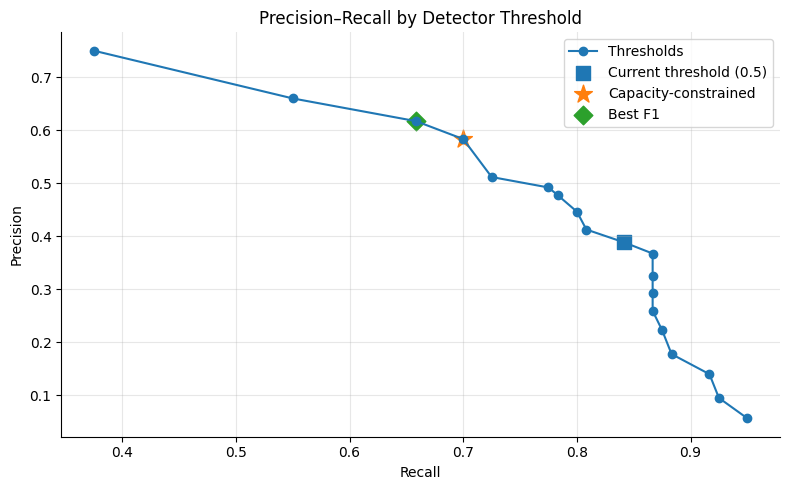

Recommendation: use threshold 0.80 to capture the highest recall within capacity (144 alerts, recall 70.00%, precision 58.33%); best-F1 threshold is 0.85.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the already-loaded transaction DataFrame
# Assumes detector_score is the model score and is_fraud is the confirmed label.
y_true = tx["is_fraud"].astype(bool).to_numpy()
scores = pd.to_numeric(tx["detector_score"], errors="coerce").to_numpy()

rows = []

# TODO 1: Evaluate thresholds from 0.05 to 0.95
for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    predicted = scores >= threshold

    tp = int(np.sum(predicted & y_true))
    fp = int(np.sum(predicted & ~y_true))
    fn = int(np.sum(~predicted & y_true))
    alerts = int(np.sum(predicted))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    rows.append({
        "threshold": threshold,
        "alerts": alerts,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Capacity-constrained choice and best-F1 choice
eligible = pr[pr["alerts"] <= 150]

if eligible.empty:
    capacity_choice = None
    print("No tested threshold meets the 150-alert capacity.")
else:
    capacity_choice = eligible.sort_values(
        ["recall", "threshold"],
        ascending=[False, False]
    ).iloc[0]

best_f1 = pr.loc[pr["F1"].idxmax()]

print("Capacity-constrained choice:")
print(capacity_choice if capacity_choice is not None else "None")

print("\nBest-F1 choice:")
print(best_f1)

# TODO 3: Precision-recall curve with marked choices
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pr["recall"], pr["precision"], "o-", label="Thresholds")

current = pr.iloc[(pr["threshold"] - 0.50).abs().argmin()]
ax.scatter(current["recall"], current["precision"],
           marker="s", s=100, label="Current threshold (0.5)")

if capacity_choice is not None:
    ax.scatter(capacity_choice["recall"], capacity_choice["precision"],
               marker="*", s=180, label="Capacity-constrained")

ax.scatter(best_f1["recall"], best_f1["precision"],
           marker="D", s=90, label="Best F1")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall by Detector Threshold")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# TODO 4: One-line recommendation
if capacity_choice is not None:
    print(
        f"Recommendation: use threshold {capacity_choice['threshold']:.2f} "
        f"to capture the highest recall within capacity "
        f"({int(capacity_choice['alerts'])} alerts, "
        f"recall {capacity_choice['recall']:.2%}, "
        f"precision {capacity_choice['precision']:.2%}); "
        f"best-F1 threshold is {best_f1['threshold']:.2f}."
    )
else:
    print(
        f"Recommendation: none of the tested thresholds meets the "
        f"150-alert limit; review a higher threshold or revise capacity. "
        f"Best-F1 threshold is {best_f1['threshold']:.2f}."
    )


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The Head of Fraud Ops should make the final decision, not the model, because the threshold involves a business trade-off between catching more fraud (recall), avoiding false alarms (precision), and staying within the team’s capacity of 150 alerts per month. Visual analytics keeps a human in the loop because the model provides evidence through metrics and visualizations, while the human applies operational constraints, risk tolerance, and domain knowledge to choose the most appropriate threshold.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [ ]:

import pandas as pd
import plotly.express as px

# TODO 1: Interactive scatter plot with details-on-demand
flagged = tx[pd.to_numeric(tx["detector_score"], errors="coerce") >= 0.3].copy()

flagged["timestamp"] = pd.to_datetime(flagged["timestamp"], errors="coerce")

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data={
        "txn_id": True,
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": True,
        "detector_score": ":.3f",
        "timestamp": True,
        "amount_inr": ":.2f"
    },
    title="Flagged Transactions (Detector Score ≥ 0.3)",
    labels={
        "timestamp": "Transaction Timestamp",
        "amount_inr": "Transaction Amount (INR)",
        "label": "Transaction Label"
    }
)

fig_scatter.update_layout(dragmode="select")
fig_scatter.show()


# TODO 2: Interactive sunburst — City → Merchant Category
sunburst_data = tx.copy()

sunburst_data["is_fraud_num"] = pd.to_numeric(
    sunburst_data["is_fraud"], errors="coerce"
).fillna(0)

sunburst = (
    sunburst_data
    .groupby(["city", "merchant_category"], dropna=False)
    .agg(
        transaction_count=("txn_id", "count"),
        fraud_count=("is_fraud_num", "sum")
    )
    .reset_index()
)

sunburst["fraud_rate"] = (
    sunburst["fraud_count"] / sunburst["transaction_count"]
)

fig_sunburst = px.sunburst(
    sunburst,
    path=["city", "merchant_category"],
    values="transaction_count",
    color="fraud_rate",
    color_continuous_scale="RdYlGn_r",
    range_color=(0, 1),
    hover_data={
        "transaction_count": True,
        "fraud_count": True,
        "fraud_rate": ":.1%"
    },
    title="Transaction Drill-Down: City → Merchant Category",
    labels={
        "transaction_count": "Transactions",
        "fraud_count": "Confirmed Fraud Cases",
        "fraud_rate": "Fraud Rate"
    }
)

fig_sunburst.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ Tooltips are frustrating for reviewing 400 flagged cases because investigators would have to hover over each point individually, making it slow and difficult to identify overall patterns or compare cases. The interactive scatter plot fixes this by displaying all flagged transactions together, allowing investigators to spot clusters, outliers, and patterns visually, then use tooltips to inspect individual cases when needed.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: fraud is unusually concentrated in REPLACE_WITH_CITY_FROM_TASK_1, days 1–5.
Fraud rate inside window:  nan%
Fraud rate outside window: 2.17%
Chi-square statistic: 0.000
p-value: 1

Counter-example search:
                  Group  Transactions  Fraud cases Fraud rate
                 Window             0            0      0.00%
  Same city, other days             0            0      0.00%
Other cities, same days           856           18      2.10%
                   Rest          4664          102      2.19%


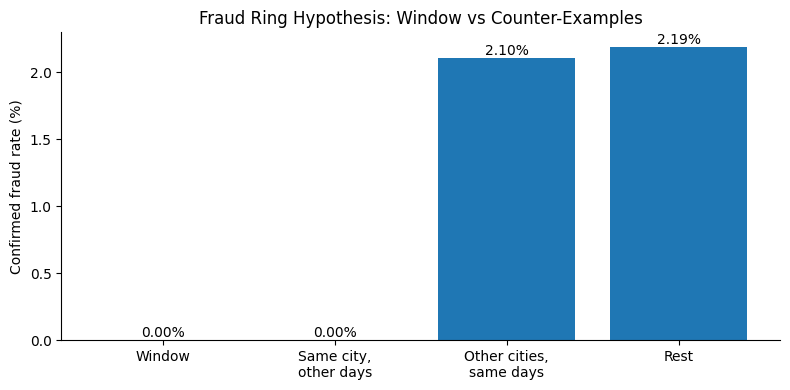

VERDICT: Inconclusive — the selected window has no transactions.


In [ ]:

from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# TODO 1: State the hypothesis using your Task 1 findings
target_city = "REPLACE_WITH_CITY_FROM_TASK_1"
start_day = 1   # Replace with the first day in your cluster
end_day = 5     # Replace with the last day in your cluster

in_window = (
    tx["city"].eq(target_city)
    & tx["day"].between(start_day, end_day)
)

# Normalize the confirmed-fraud flag (supports 0/1, Boolean, or text labels)
s = tx["is_fraud"]
if pd.api.types.is_bool_dtype(s):
    fraud = s.fillna(False)
elif pd.api.types.is_numeric_dtype(s):
    fraud = s.fillna(0).eq(1)
else:
    fraud = s.astype(str).str.strip().str.lower().isin(
        ["1", "true", "yes", "fraud"]
    )

print(
    f"Hypothesis: fraud is unusually concentrated in {target_city}, "
    f"days {start_day}–{end_day}."
)

# TODO 2: Fraud rate inside vs outside + chi-square test
inside_rate = fraud[in_window].mean() if in_window.any() else np.nan
outside_rate = fraud[~in_window].mean() if (~in_window).any() else np.nan

contingency = pd.crosstab(in_window, fraud)
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Fraud rate inside window:  {inside_rate:.2%}")
print(f"Fraud rate outside window: {outside_rate:.2%}")
print(f"Chi-square statistic: {chi2:.3f}")
print(f"p-value: {p_value:.6g}")

# TODO 3: Search for counter-examples
same_city_other_days = tx["city"].eq(target_city) & ~tx["day"].between(
    start_day, end_day
)
other_cities_same_days = (
    tx["city"].ne(target_city) & tx["day"].between(start_day, end_day)
)
rest = ~(in_window | same_city_other_days | other_cities_same_days)

groups = {
    "Window": in_window,
    "Same city,\nother days": same_city_other_days,
    "Other cities,\nsame days": other_cities_same_days,
    "Rest": rest
}

summary = []
for name, mask in groups.items():
    count = int(mask.sum())
    fraud_count = int(fraud[mask].sum())
    rate = fraud_count / count if count else 0
    summary.append({
        "Group": name.replace("\n", " "),
        "Transactions": count,
        "Fraud cases": fraud_count,
        "Fraud rate": rate
    })

summary_df = pd.DataFrame(summary)
print("\nCounter-example search:")
print(summary_df.to_string(
    index=False,
    formatters={"Fraud rate": lambda x: f"{x:.2%}"}
))

# TODO 4: Visual comparison of the four groups
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    list(groups.keys()),
    [row["Fraud rate"] * 100 for row in summary],
)
ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Fraud Ring Hypothesis: Window vs Counter-Examples")
ax.bar_label(bars, fmt="%.2f%%")
plt.tight_layout()
plt.show()

# TODO 5: Verdict — statistical evidence, not proof of a fraud ring
if np.isnan(inside_rate) or not in_window.any():
    print("VERDICT: Inconclusive — the selected window has no transactions.")
elif p_value < 0.05 and inside_rate > outside_rate:
    print(
        "VERDICT: The window has a statistically significant higher fraud rate. "
        "Investigate further, but this alone does NOT prove a fraud ring."
    )
else:
    print(
        "VERDICT: The evidence does not establish a significantly elevated "
        "fraud rate in the selected window. Do not escalate based on this "
        "hypothesis alone."
    )


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_If the fraud rate in the same city on other days were similarly high, it would weaken the hypothesis of a time-specific fraud ring and suggest that the city has a consistently higher fraud rate. If other cities on the same days also showed similarly high fraud rates, it would suggest a broader time-related cause, such as a system-wide attack, rather than a fraud ring concentrated in one city.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_ **To: Head of Fraud Ops — Monthly Fraud Review**

Last month, the detector flagged **[number] transactions**, of which **[number] were confirmed fraud**, with the overview revealing potential city–day concentrations that require further investigation. I recommend setting the alert threshold to **[capacity-constrained threshold]**, because it keeps alerts within the 150-alert capacity while balancing precision and recall; the final decision should remain with the Head of Fraud Ops, using model metrics and operational risk rather than blindly trusting the model. We should build the **interactive scatter plot of flagged transactions** first, as it provides an overview of suspicious activity and uses *details-on-demand* tooltips to inspect individual cases. Dynamic queries should also be optimized to meet the **0.1-second response-time budget**, so investigators can filter and explore transactions smoothly. Finally, we should introduce a **human-feedback loop** in which investigators label confirmed fraud and false positives, and those reviewed outcomes are used to retrain and improve next month’s detector.